# Projeto 2 - CB - O que está associado aos atrasos das maiores companhias aéreas brasileiras?

**Autores:**
- Anna Albuquerque
- Mateus Cortez Camacho

---

Os **atrasos em voos** são relevantes tanto para passageiros, que perdem conexões e compromissos, quanto para as companhias aéreas e os aeroportos, que arcam com custos operacionais e de reputação. Este trabalho investiga quais características dos voos apresentam maior relação com o atraso nas três maiores companhias aéreas do Brasil (LATAM, GOL e Azul) e se as diferenças entre elas se mantêm quando se consideram fatores como aeroporto e horário.

---

### Variáveis
- **Sigla ICAO Empresa Aérea**: Código ICAO da companhia aérea (ex.: AZU = Azul, TAM = LATAM Brasil, GLO = GOL) - *Qualitativa Nominal*
- **Empresa Aérea**: Nome da companhia aérea - *Qualitativa Nominal*
- **Número Voo**: Número do voo - *Identificação*
- **Código DI**: Código que identifica a natureza do voo (0 = voo regular) - *Qualitativa Nominal*
- **Código Tipo Linha**: Tipo de linha (N = doméstica mista, I = internacional mista, C = doméstica cargueira, G = internacional cargueira) - *Qualitativa Nominal*
- **Modelo Equipamento**: Modelo da aeronave (ex.: A320, B738) - *Qualitativa Nominal*
- **Número de Assentos**: Quantidade de assentos da aeronave - *Quantitativa Discreta*
- **Sigla ICAO Aeroporto Origem**: Código ICAO do aeroporto de partida (ex.: SBGR = Guarulhos) - *Qualitativa Nominal*
- **Descrição Aeroporto Origem**: Nome, cidade e UF do aeroporto de partida - *Qualitativa Nominal*
- **Partida Prevista**: Data e hora programadas para a partida - *Data/Hora*
- **Partida Real**: Data e hora em que a partida ocorreu - *Data/Hora*
- **Sigla ICAO Aeroporto Destino**: Código ICAO do aeroporto de chegada - *Qualitativa Nominal*
- **Descrição Aeroporto Destino**: Nome, cidade e UF do aeroporto de chegada - *Qualitativa Nominal*
- **Chegada Prevista**: Data e hora programadas para a chegada - *Data/Hora*
- **Chegada Real**: Data e hora em que a chegada ocorreu - *Data/Hora*
- **Situação Voo**: Se o voo foi realizado ou cancelado - *Qualitativa Nominal Binária*
- **Justificativa**: Motivo do atraso ou cancelamento (coluna 100% vazia nesta base) - *Qualitativa Nominal*
- **Referência**: Data de referência do voo - *Data*
- **Situação Partida**: Faixa de pontualidade da partida (Antecipado, Pontual, Atraso 30-60, 60-120, 120-240, …) - *Qualitativa Ordinal*
- **Situação Chegada**: Faixa de pontualidade da chegada (mesmas categorias) - *Qualitativa Ordinal*
- **Codeshare**: Companhia parceira e número do voo compartilhado, quando houver (vazio na maioria dos voos) - *Qualitativa Nominal*

### Bibliotecas Principais

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Importação da DF

In [2]:
import pandas as pd

df = pd.read_csv(
    "VRA_2025_01.csv",
    sep=";",
    encoding="utf-8",
    dtype={"Número Voo": str},  # mantém zeros à esquerda (ex.: "0904")
)

# no CSV as datas vêm como texto ("01/01/2025 23:55"); converter para data/hora
for col in ["Partida Prevista", "Partida Real", "Chegada Prevista", "Chegada Real", "Referência"]:
    df[col] = pd.to_datetime(df[col], dayfirst=True)

print(df.shape)
df.head()

(89616, 21)


,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,Sigla ICAO Aeroporto Origem,Descrição Aeroporto Origem,Partida Prevista,...,Sigla ICAO Aeroporto Destino,Descrição Aeroporto Destino,Chegada Prevista,Chegada Real,Situação Voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare
0,AAL,"AMERICAN AIRLINES, INC.",0904,0,I,B788,295,SBGL,AEROPORTO INTERNACIONAL DO RIO DE JANEIRO (GAL...,2025-01-01 23:55:00,...,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-02 07:45:00,2025-01-02 08:11:00,REALIZADO,NaN,2025-01-01,Antecipado,Pontual,NaN
1,AAL,"AMERICAN AIRLINES, INC.",0905,0,I,B788,295,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 01:10:00,...,SBGL,AEROPORTO INTERNACIONAL DO RIO DE JANEIRO (GAL...,2025-01-01 09:25:00,2025-01-01 09:24:00,REALIZADO,NaN,2025-01-01,Pontual,Antecipado,NaN
2,AAL,"AMERICAN AIRLINES, INC.",0906,0,I,B77W,318,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-01 00:30:00,...,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 08:55:00,2025-01-01 08:31:00,REALIZADO,NaN,2025-01-01,Antecipado,Antecipado,NaN
3,AAL,"AMERICAN AIRLINES, INC.",0925,0,I,B772,288,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 23:50:00,...,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-02 08:10:00,2025-01-02 08:37:00,REALIZADO,NaN,2025-01-01,Pontual,Pontual,NaN
4,AAL,"AMERICAN AIRLINES, INC.",0929,0,I,B77W,318,KMIA,"MIAMI INTERNATIONAL AIRPORT - MIAMI, FLORIDA -...",2025-01-01 20:50:00,...,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2025-01-02 06:20:00,2025-01-02 06:44:00,REALIZADO,NaN,2025-01-01,Atraso 60-120,Pontual,NaN


### Tamanho do DF - 89616 Linhas e 21 Colunas

In [3]:
df.shape


(89616, 21)

### Tipos de Variáveis

In [4]:
df.dtypes

Sigla ICAO Empresa Aérea                   str
Empresa Aérea                              str
Número Voo                                 str
Código DI                                  str
Código Tipo Linha                          str
Modelo Equipamento                         str
Número de Assentos                       int64
Sigla ICAO Aeroporto Origem                str
Descrição Aeroporto Origem                 str
Partida Prevista                datetime64[us]
Partida Real                    datetime64[us]
Sigla ICAO Aeroporto Destino               str
Descrição Aeroporto Destino                str
Chegada Prevista                datetime64[us]
Chegada Real                    datetime64[us]
Situação Voo                               str
Justificativa                          float64
Referência                      datetime64[us]
Situação Partida                           str
Situação Chegada                           str
Codeshare                                  str
dtype: object

### Variável atraso_chegada - Indica a variação entre o horário de saída esperado e o que realmente ocorreu
### Variável atrasou_15 - Indica quantos voos atrasaram mais de 15 minutos (1)

In [5]:
# atraso de chegada em minutos (positivo = atrasou, negativo = chegou antes)
df["atraso_chegada"] = (df["Chegada Real"] - df["Chegada Prevista"]).dt.total_seconds() / 60

# versão binária: 1 = atrasou mais de 15 min, 0 = não atrasou
# voos sem atraso calculável ficam vazios (NA), e não como "não atrasou"
df["atrasou_15"] = (df["atraso_chegada"] > 15).astype("Int64").mask(df["atraso_chegada"].isna())

# checagens
print(df["atraso_chegada"].describe())
print(df["atrasou_15"].value_counts(dropna=False))

count    84123.000000
mean         4.276191
std        164.490535
min       -997.000000
25%        -13.000000
50%         -4.000000
75%          7.000000
max      44625.000000
Name: atraso_chegada, dtype: float64
atrasou_15
0       70364
1       13759
<NA>     5493
Name: count, dtype: Int64


### Quantidade de empresas no df (76), filtro apenas pras 10 mais relevantes no gráfico

Total de empresas na base: 76
Azul, LATAM e GOL: 73,067 de 89,616 voos (81.5%)


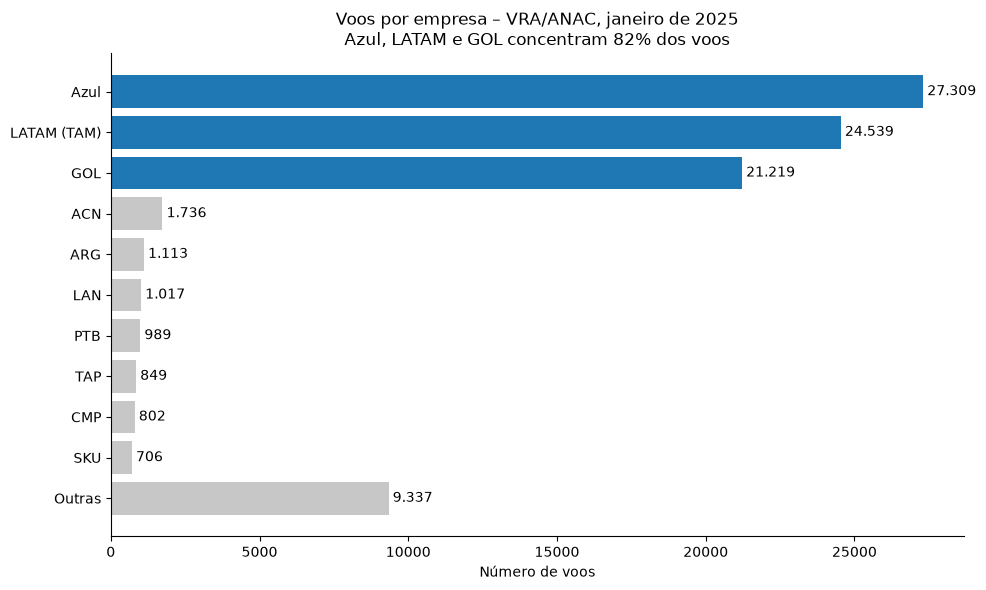

In [13]:
import matplotlib.pyplot as plt

# contagem de voos por empresa
contagem = df["Sigla ICAO Empresa Aérea"].value_counts()
print(f"Total de empresas na base: {len(contagem)}")

# participação das três maiores
tres = ["AZU", "TAM", "GLO"]
participacao = contagem[tres].sum() / contagem.sum() * 100
print(f"Azul, LATAM e GOL: {contagem[tres].sum():,} de {contagem.sum():,} voos ({participacao:.1f}%)")

# top 10 empresas + o restante agrupado em "Outras"
top = contagem.head(10).copy()
top["Outras"] = contagem.iloc[10:].sum()

# nomes legíveis para as três principais
nomes = {"AZU": "Azul", "TAM": "LATAM (TAM)", "GLO": "GOL"}
rotulos = [nomes.get(sigla, sigla) for sigla in top.index]
cores = ["#1f77b4" if sigla in tres else "#c7c7c7" for sigla in top.index]

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(rotulos[::-1], top.values[::-1], color=cores[::-1])
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in top.values[::-1]], padding=3)
ax.set_xlabel("Número de voos")
ax.set_title(f"Voos por empresa – VRA/ANAC, janeiro de 2025\n"
             f"Azul, LATAM e GOL concentram {participacao:.0f}% dos voos")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Criação do df3, dataframe filtrando as 3 empresas mais relevantes (AZU, TAM, GLO)

In [7]:
pd.set_option("display.max_columns", None)  # mostra todas as colunas nas tabelas

# filtrar as três companhias
companhias = ["AZU", "TAM", "GLO"]
df3 = df[df["Sigla ICAO Empresa Aérea"].isin(companhias)].copy()
print(df3.shape)

(73067, 23)


### Análisar Outliers no atraso de df3


In [8]:
# distribuição do atraso, com percentis extremos
print(df3["atraso_chegada"].describe(percentiles=[.01, .25, .5, .75, .99]))

# quantos voos passam de cada corte
for corte in [120, 240, 600, 1440]:
    print(f"\nAtraso > {corte} min: {(df3['atraso_chegada'] > corte).sum()} voos")

count    70377.000000
mean         1.446026
std         43.683182
min        -79.000000
1%         -30.000000
25%        -13.000000
50%         -5.000000
75%          6.000000
99%        107.000000
max       2866.000000
Name: atraso_chegada, dtype: float64

Atraso > 120 min: 570 voos

Atraso > 240 min: 133 voos

Atraso > 600 min: 36 voos

Atraso > 1440 min: 7 voos


<Axes: ylabel='atraso_chegada'>

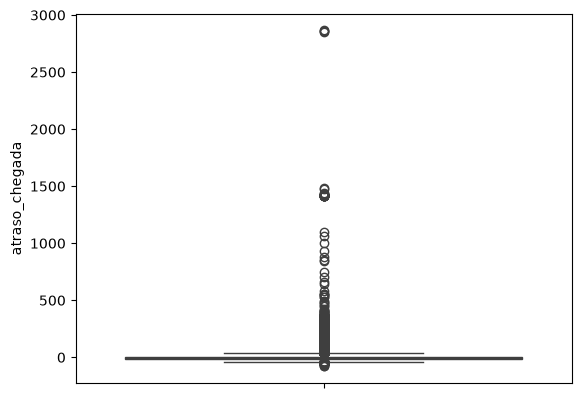

In [9]:
sns.boxplot(y = df3['atraso_chegada'])

### Remoção de Outliers, atrasos acima de 600 minutos

In [10]:
antes = len(df3)

# remove só os voos com atraso acima de 600 min; mantém os sem atraso calculável (NaN)
df3 = df3[~(df3["atraso_chegada"] > 600)]

print(f"Removidos {antes - len(df3)} voos com atraso > 600 min")
print(df3["atraso_chegada"].describe())

Removidos 36 voos com atraso > 600 min
count    70341.000000
mean         0.724471
std         26.838185
min        -79.000000
25%        -13.000000
50%         -5.000000
75%          6.000000
max        584.000000
Name: atraso_chegada, dtype: float64


<Axes: ylabel='atraso_chegada'>

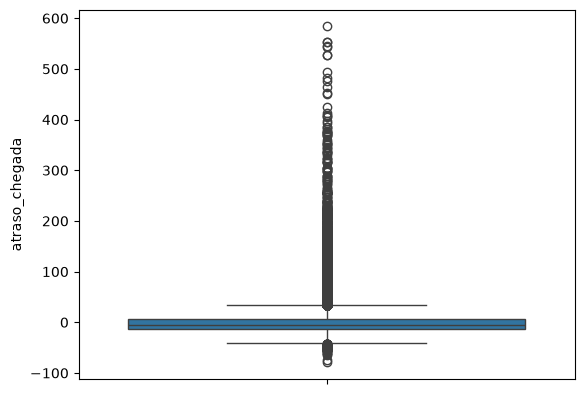

In [11]:
sns.boxplot(y = df3['atraso_chegada'])